# AS4 Q-Learning Training, Evaluation, and Report Evidence

This notebook is the experiment controller for the AS4 Godot 2D Platform Collector. Python launches the Godot project through `AS4GodotEnv`, exchanges JSON reset/step messages over local WebSocket port `8765`, trains **tabular Q-learning** agents sequentially, evaluates saved Q-tables, and exports report-ready CSV files and figures.

This is a converted version of the original PPO notebook. Because Q-learning of the classic tabular kind needs a *discrete* state space, and `AS4GodotEnv` exposes twelve continuous observations, the biggest structural change from the PPO notebook is a discretization step that turns each continuous observation into a small integer grid cell before it is used as a Q-table key. Everything downstream (evaluation, plotting, checkpoint screening, multi-seed validation) mirrors the original PPO notebook's structure so the two experiments stay directly comparable.

### Execution order and purpose

1. **Set up reproducibility and paths** so every run uses known software, seeds, folders, and queue controls.
2. **Define the state discretization** used to turn continuous observations into Q-table keys.
3. **Validate the Gymnasium–Godot boundary** before spending time on training.
4. **Measure a random-agent control** to establish the untrained performance floor.
5. **Resolve seven controlled Q-learning configurations** from one baseline plus one-parameter alternatives.
6. **Train sequentially** because all environments share WebSocket port `8765`.
7. **Screen checkpoints** and retain the strongest checkpoint for each configuration.
8. **Evaluate greedy and epsilon-greedy policies** with a common episode budget.
9. **Generate tables and plots** for comparison, diagnosis, and the assignment report.
10. **Repeat training across additional seeds** to estimate sensitivity to initialization.

When `SKIP_COMPLETED_MODELS` is enabled, existing final Q-table files are reused. This supports recovery after an interrupted long run, but those files must belong to the same observation space, discretization, reward design, and experiment version.

## 1. Environment and reinforcement-learning formulation

The environment logic is implemented across `main.gd`, `player.gd`, `apple.gd`, `snail.gd`, and `websocket_bridge.gd`; `as4_env.py` exposes that game as a Gymnasium environment. `as4_env.py` itself is algorithm-agnostic and is unchanged from the PPO version of this project.

### Observation space: 12 normalized values

| Index | Observation | Purpose |
|---:|---|---|
| 0–1 | Player x/y position | Locates the agent within the level. |
| 2–3 | Horizontal/vertical velocity | Represents current motion and jump phase. |
| 4 | On-floor flag | Indicates whether a jump can begin. |
| 5 | Touching-wall flag | Helps distinguish blocked movement. |
| 6 | Horizontal wall normal | Identifies which side is obstructed. |
| 7–8 | Relative x/y position of the active navigation target | Directs the policy toward the next reachable objective. |
| 9–10 | Relative x/y position of the nearest active snail | Supports enemy avoidance. |
| 11 | Fraction of apples remaining | Represents task progress. |

The active navigation target is normally the nearest apple. After the lower apple is collected, `main.gd` temporarily exposes a central-platform approach waypoint so both the observation and distance shaping describe a reachable route around the wall.

### Discrete action space

| Value | Action | Purpose |
|---:|---|---|
| 0 | Do nothing | Allows waiting or preserving a trajectory. |
| 1 | Move left | Horizontal control. |
| 2 | Move right | Horizontal control. |
| 3 | Jump | Vertical control without horizontal input. |
| 4 | Move left and jump | Combined platforming action. |
| 5 | Move right and jump | Combined platforming action. |

### Reward and termination design

| Event | Reward | Purpose |
|---|---:|---|
| Each decision step | −0.01 | Discourages unnecessarily long episodes. |
| Reach the upper-apple waypoint once | +4 | Rewards the required detour. |
| Collect an apple | +5 | Rewards partial task progress. |
| Collect all apples | +20 | Rewards successful completion and terminates the episode. |
| Hit an enemy | −10 | Penalizes unsafe movement and terminates the episode. |
| Fall below the level | −10 | Penalizes falling and terminates the episode. |
| Reach 1,000 decisions | −8 | Ends the episode as a Gymnasium truncation. |
| Move toward/away from the active target | Clipped to [−0.1, +0.1] | Supplies dense progress feedback without overwhelming event rewards. |

`websocket_bridge.gd` pauses the scene between requests. One Python action is held for four Godot physics ticks, so movement, collisions, rewards, and the returned transition stay synchronized.

### State discretization for tabular Q-learning

Tabular Q-learning keeps one row of action-values per *discrete* state, so the twelve continuous observations above are each cut into a small number of equal-width bins before being used as a Q-table key. Binary flags (on-floor, touching-wall) get exactly two bins so no information is lost; position, velocity, and relative-distance observations get coarser bins because the table would otherwise never revisit the same state twice. `BINS_PER_DIMENSION` (Section 2.2) fixes this grid, and it is held constant across every configuration so configurations differ only in their learning hyperparameters, mirroring how the PPO notebook kept the network architecture constant across its seven configurations.

## 2. Setup and reproducibility

The next cell imports the numerical, plotting, Gymnasium, and WebSocket libraries used throughout the notebook, plus Python's standard `pickle`/`csv`/`json` modules used to save Q-tables and write training logs in the same CSV format the plotting cells expect. It seeds Python's and NumPy's random number generators with `SEED = 123`. Tabular Q-learning has no neural network, so PyTorch and Stable-Baselines3's `PPO` are no longer needed; `stable_baselines3.common.env_checker.check_env` is kept because it validates the Gymnasium interface itself, independent of which algorithm is used.

In [1]:
import csv
import json
import pickle
import platform
import random
import shutil
import sys
import time
from pathlib import Path

import gymnasium
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import websockets
from stable_baselines3.common.env_checker import check_env

SEED = 123
random.seed(SEED)
np.random.seed(SEED)
experiment_metrics = []
HEADLESS = True

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Platform:", platform.platform())
print("Gymnasium:", gymnasium.__version__)
print("WebSockets:", websockets.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)

Python executable: d:\GitHub\UCCD2063-Artificial-Intelligence-Techniques-RL-Godot\.conda\python.exe
Python version: 3.14.7 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 10:12:46) [MSC v.1942 64 bit (AMD64)]
Platform: Windows-11-10.0.26200-SP0
Gymnasium: 1.3.0
WebSockets: 17.0.1
NumPy: 2.5.2
Pandas: 3.0.5
Matplotlib: 3.11.1


### 2.1 Project paths and execution controls

The next cell searches upward from the current working directory for `project.godot`, creates canonical `results/` and `models/` folders, and adds `agent/` to Python's import path before importing `AS4GodotEnv`.

The control variables separate quick checks from expensive work:

- `HEADLESS` controls rendering; headless mode is intended for faster training.
- `TRAIN_EXPERIMENTS` enables or disables the main training queue.
- `SKIP_COMPLETED_MODELS` supports resuming from existing final Q-table files.
- `SMOKE_TEST_TIMESTEPS` and `TARGET_TOTAL_TIMESTEPS` define the short preflight stage and full per-model budget, counted in environment steps rather than PPO rollout timesteps, but otherwise serving the same purpose.
- Episode counts define random, checkpoint-screening, and final-evaluation sample sizes.
- `EXPERIMENT_NAMES_TO_RUN` selects all seven active configurations.

`CONFIG_DIRECTORY` is kept only for parity with the PPO notebook's unused `ppo_configs/` path; active configurations are defined directly in code and do not use that directory.

In [2]:
# Locate the repository from the notebook directory or any parent directory.
# Specifically target the 'as-4' folder containing project.godot to avoid opening other assignments (like as-3).
cwd = Path.cwd().resolve()
AS4_DIRECTORY = None
if cwd.name == "as-4" and (cwd / "project.godot").exists():
    AS4_DIRECTORY = cwd
elif cwd.parent.name == "as-4" and (cwd.parent / "project.godot").exists():
    AS4_DIRECTORY = cwd.parent
else:
    for parent in [cwd, *cwd.parents]:
        as4_path = parent / "as-4"
        if as4_path.exists() and (as4_path / "project.godot").exists():
            AS4_DIRECTORY = as4_path
            break
        if (parent / "project.godot").exists() and parent.name == "as-4":
            AS4_DIRECTORY = parent
            break
if AS4_DIRECTORY is None:
    raise FileNotFoundError(
        "Could not locate the AS4 Godot project (project.godot) from the current directory"
    )

AGENT_DIRECTORY = AS4_DIRECTORY / "agent"
CONFIG_DIRECTORY = AGENT_DIRECTORY / "q_configs"
RESULTS_DIRECTORY = AS4_DIRECTORY / "results"
MODELS_DIRECTORY = AS4_DIRECTORY / "models"
RESULTS_DIRECTORY.mkdir(parents=True, exist_ok=True)
MODELS_DIRECTORY.mkdir(parents=True, exist_ok=True)

if str(AGENT_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(AGENT_DIRECTORY))

# Embedded gymnasium environment from as4_env.py
import json
import os
import queue
import shutil
import subprocess
import threading
from websockets.exceptions import ConnectionClosed
from websockets.sync.server import ServerConnection, serve
import gymnasium as gym

def _resolve_godot_executable() -> Path:
    """Locate Godot while allowing an explicit machine-specific override."""

    override = os.environ.get("GODOT_EXECUTABLE")
    if override:
        return Path(override).expanduser()

    # Command-line installations normally expose one of these executable names.
    command = shutil.which("godot") or shutil.which("godot4")
    if command:
        return Path(command)

    # Default location used by the official macOS application bundle.
    return Path(r"D:\Downloads\Godot_v4.7.1-stable_mono_win64\Godot_v4.7.1-stable_mono_win64\Godot_v4.7.1-stable_mono_win64.exe")


GODOT_EXECUTABLE = _resolve_godot_executable()

# Resolve the Godot project relative to this module so the repository can be
# moved or opened on another group member's machine without editing source code.
PROJECT_DIRECTORY = AS4_DIRECTORY


class GodotWebSocketServer:
    """Runs a local WebSocket server and exchanges JSON messages with Godot."""

    def __init__(
        self,
        host: str = "127.0.0.1",
        port: int = 8765,
        timeout: float = 30.0,
    ) -> None:
        self.host = host
        self.port = port
        self.timeout = timeout

        self._connection: ServerConnection | None = None
        self._server = None

        # Events allow the main thread to wait until the server and Godot are ready.
        self._server_ready = threading.Event()
        self._godot_connected = threading.Event()

        # Godot responses are placed here by the connection-handling thread.
        self._response_queue: queue.Queue[dict[str, Any]] = queue.Queue()

        # Only one reset or step request may be active at one time.
        self._request_lock = threading.Lock()

        self._thread = threading.Thread(
            target=self._run_server,
            name=f"godot-websocket-server-{port}",
            daemon=True,
        )

    def start(self) -> None:
        """Start the WebSocket server in a background thread."""

        self._thread.start()

        if not self._server_ready.wait(self.timeout):
            raise TimeoutError("WebSocket server did not start")

    def wait_for_godot(self) -> None:
        """Wait until the Godot WebSocket client connects."""

        if not self._godot_connected.wait(self.timeout):
            raise TimeoutError("Godot did not connect to the WebSocket server")

    def request(self, payload: dict[str, Any]) -> dict[str, Any]:
        """Send one request and block until its matching response arrives."""

        with self._request_lock:
            if self._connection is None:
                raise ConnectionError("Godot WebSocket is not connected")

            # Remove an unexpected stale response before sending a new request.
            while not self._response_queue.empty():
                self._response_queue.get_nowait()

            self._connection.send(json.dumps(payload))

            try:
                response = self._response_queue.get(timeout=self.timeout)
            except queue.Empty as error:
                raise TimeoutError(
                    f"Godot did not answer request: {payload}"
                ) from error

            if response.get("type") == "error":
                raise RuntimeError(
                    f"Godot error: {response.get('message', 'unknown error')}"
                )

            return response

    def close(self) -> None:
        """Stop accepting connections and close the WebSocket server."""

        if self._server is not None:
            self._server.shutdown()

    def _run_server(self) -> None:
        """Create the server and keep it running until close() is called."""

        with serve(
            self._handle_connection,
            self.host,
            self.port,
            ping_interval=20,
            ping_timeout=20,
        ) as server:
            self._server = server
            self._server_ready.set()
            server.serve_forever()

    def _handle_connection(
        self,
        websocket: ServerConnection,
    ) -> None:
        """Receive every JSON response sent by the connected Godot process."""

        self._connection = websocket
        self._godot_connected.set()

        try:
            for message in websocket:
                response = json.loads(message)
                self._response_queue.put(response)
        except ConnectionClosed:
            # A disconnect is expected when close() shuts down Godot and the
            # local WebSocket server at the end of a test or training run.
            pass
        finally:
            if self._connection is websocket:
                self._connection = None
                self._godot_connected.clear()


class AS4GodotEnv(gym.Env[np.ndarray, int]):
    """Gymnasium wrapper for the AS4 Godot platform environment.

    AS4's level_root.tscn places two Snail enemies (Enemies/Snail,
    Enemies/Snail2) and two Apple pickups (Apple/Apple, Apple/Apple2)
    instead of AS1's one of each. The observation and action definitions
    below are otherwise identical to AS1GodotEnv, since main.gd is assumed
    to already report only the nearest active apple/waypoint and the
    nearest active snail rather than one slot per entity.
    """

    metadata = {"render_modes": ["human"]}

    def __init__(
        self,
        headless: bool = False,
        request_timeout: float = 30.0,
        port: int = 8765,
    ) -> None:
        super().__init__()

        if not GODOT_EXECUTABLE.exists():
            raise FileNotFoundError(f"Godot executable not found: {GODOT_EXECUTABLE}")

        if not (PROJECT_DIRECTORY / "project.godot").exists():
            raise FileNotFoundError(f"Godot project not found: {PROJECT_DIRECTORY}")

        # The agent can select one of six integer actions.
        self.action_space = gym.spaces.Discrete(6)

        # Exact boundaries corresponding, in order, to main.gd's twelve
        # normalized observations. Keeping both definitions synchronized lets
        # Gymnasium reject malformed or out-of-range states before the agent
        # sees them.
        self.observation_space = gym.spaces.Box(
            low=np.array(
                [
                    0.0,  # player x
                    -0.5,  # player y
                    -1.0,  # horizontal velocity
                    -2.0,  # vertical velocity
                    0.0,  # is_on_floor
                    0.0,  # is touching wall
                    -1.0,  # wall-normal x
                    -1.0,  # nearest active apple/waypoint dx
                    -1.0,  # nearest active apple/waypoint dy
                    -1.0,  # nearest active snail dx
                    -1.0,  # nearest active snail dy
                    0.0,  # apples remaining
                ],
                dtype=np.float32,
            ),
            high=np.array(
                [
                    1.5,  # player x
                    1.5,  # player y
                    1.0,  # horizontal velocity
                    2.0,  # vertical velocity
                    1.0,  # is_on_floor
                    1.0,  # is touching wall
                    1.0,  # wall-normal x
                    1.0,  # nearest active apple/waypoint dx
                    1.0,  # nearest active apple/waypoint dy
                    1.0,  # nearest active snail dx
                    1.0,  # nearest active snail dy
                    1.0,  # apples remaining
                ],
                dtype=np.float32,
            ),
            dtype=np.float32,
        )

        self.port = port
        self.bridge = GodotWebSocketServer(port=port, timeout=request_timeout)
        self.bridge.start()

        # Start Godot only after Python is ready to accept its connection.
        command = [
            str(GODOT_EXECUTABLE),
            "--path",
            str(PROJECT_DIRECTORY),
        ]

        if headless:
            command.append("--headless")

        # simulate 4x faster than real-time
        command.extend(["--fixed-fps", "600"])
        command.append("--disable-vsync")

        # Everything after "--" is passed through to Godot's user args
        # (OS.get_cmdline_user_args() on the GDScript side), rather than
        # being interpreted as an engine flag. websocket_bridge.gd reads
        # "--port=<n>" from there to decide which port to connect to, so
        # each concurrently-running Godot instance can bind to a different
        # local Python WebSocket server.
        command.extend(["--", f"--port={port}"])

        self.godot_process = subprocess.Popen(command)
        self.bridge.wait_for_godot()

    def reset(
        self,
        *,
        seed: int | None = None,
        options: dict[str, Any] | None = None,
    ) -> tuple[np.ndarray, dict[str, Any]]:
        """Start a new Godot episode and return its first observation."""

        super().reset(seed=seed)

        if seed is not None:
            self.action_space.seed(seed)

        # Send reset command
        response = self.bridge.request({"command": "reset"})

        # Wait for Godot to fully reinitialize the scene before
        # Python sends the first action. Without this, the agent
        # can carry over momentum or collect a respawning apple
        # from the previous episode on the very first step.
        import time
        time.sleep(0.3)

        # Send a no-op action to flush any stale state in Godot
        # before returning the clean first observation.
        noop_response = self.bridge.request({
            "command": "step",
            "action": 0,   # do nothing
        })

        observation = self._convert_observation(noop_response["observation"])
        info = dict(noop_response.get("info", {}))

        return observation, info

    def step(
        self,
        action: int,
    ) -> tuple[np.ndarray, float, bool, bool, dict[str, Any]]:
        """Send one action to Godot and return the resulting transition."""

        if not self.action_space.contains(action):
            raise ValueError(f"Invalid action: {action}")

        response = self.bridge.request(
            {
                "command": "step",
                "action": int(action),
            }
        )

        observation = self._convert_observation(response["observation"])
        reward = float(response["reward"])
        info = dict(response.get("info", {}))

        reason = str(info.get("reason", ""))

        # These events are natural terminal states of the AS4 task.
        terminated = reason in {
            "success",
            "enemy",
            "fall",
        }

        # Timeout is an external time limit rather than a task terminal state.
        truncated = reason == "timeout"

        return observation, reward, terminated, truncated, info

    def inspect_observation(self) -> np.ndarray:
        """Read synchronized state without executing an action or physics tick."""

        response = self.bridge.request({"command": "inspect"})
        return self._convert_observation(response["observation"])

    def close(self) -> None:
        """Close Godot and the local WebSocket server."""

        # Close the WebSocket first so it can send a normal close frame while
        # Godot is still alive and polling the connection.
        if hasattr(self, "bridge"):
            self.bridge.close()

        if hasattr(self, "godot_process"):
            if self.godot_process.poll() is None:
                self.godot_process.terminate()

                try:
                    self.godot_process.wait(timeout=5)
                except subprocess.TimeoutExpired:
                    self.godot_process.kill()

        super().close()

    def _convert_observation(
        self,
        values: list[float],
    ) -> np.ndarray:
        """Convert and validate a Godot observation."""

        observation = np.asarray(values, dtype=np.float32)

        if observation.shape != self.observation_space.shape:
            raise ValueError(
                "Incorrect observation shape: "
                f"expected {self.observation_space.shape}, "
                f"received {observation.shape}"
            )

        if not np.all(np.isfinite(observation)):
            raise ValueError(f"Observation contains NaN or infinity: {observation}")

        if not self.observation_space.contains(observation):
            raise ValueError(
                f"Observation is outside its declared space: {observation}"
            )
        return observation

TRAIN_EXPERIMENTS = True
SKIP_COMPLETED_MODELS = True

# Single 2,000 episode budget configuration
TARGET_EPISODES = 3000
MAX_STEPS_PER_EPISODE = 500
TARGET_TOTAL_TIMESTEPS = 1_500_000  # 1,000,000 timesteps max

RANDOM_BASELINE_EPISODES = 50
FINAL_EVALUATION_EPISODES = 50
EVAL_STOCHASTIC_EPSILON = 0.10

# Selected configurations only
EXPERIMENT_NAMES_TO_RUN = {
    "baseline",
    "low_alpha",
    "high_alpha",
    "fast_epsilon_decay",
}



### 2.2 State discretization

`BINS_PER_DIMENSION` fixes how many equal-width bins each of the twelve observations is cut into. The two boolean flags (on-floor, touching-wall) get exactly two bins; position and relative-distance observations get more bins because they carry more task-relevant information; velocities and the wall-normal get fewer bins because coarse motion buckets are enough to distinguish "rising" from "falling" or "pushing left" from "pushing right". `STATE_SPACE_SIZE` is the theoretical number of distinct grid cells; the Q-table itself only ever allocates rows for states the agent actually visits, so this number is an upper bound, not the memory footprint.

In [3]:
# One bin count per observation, in the same order as the table in Section 1.
BINS_PER_DIMENSION = np.array([4, 4, 3, 3, 2, 2, 3, 4, 4, 4, 4, 3])

STATE_SPACE_SIZE = int(np.prod(BINS_PER_DIMENSION))
print("Bins per dimension:", BINS_PER_DIMENSION.tolist())
print(f"Theoretical state space size: {STATE_SPACE_SIZE:,} grid cells (upper bound; Q-table stores only visited states)")


def discretize_observation(observation, low, high, bins_per_dimension):
    """Map a continuous observation into a tuple of bin indices.

    The tuple is hashable, so it can be used directly as a Q-table key.
    """
    ratios = (np.asarray(observation, dtype=np.float64) - low) / (high - low)
    ratios = np.clip(ratios, 0.0, 0.999999)
    indices = (ratios * bins_per_dimension).astype(int)
    return tuple(int(i) for i in indices)

Bins per dimension: [4, 4, 3, 3, 2, 2, 3, 4, 4, 4, 4, 3]
Theoretical state space size: 1,327,104 grid cells (upper bound; Q-table stores only visited states)


In [4]:
for monitor_path in RESULTS_DIRECTORY.glob("*_monitor.csv"):
    with open(monitor_path, "r") as f:
        lines = f.readlines()
 
    if lines and not lines[0].startswith("#"):
        lines[0] = "#" + lines[0]
        with open(monitor_path, "w") as f:
            f.writelines(lines)
        print(f"Patched: {monitor_path.name}")
    else:
        print(f"Already OK: {monitor_path.name}")

## 3. Reusable evaluation and plotting functions

The next cell centralizes operations that must remain consistent across policies:

- `run_episodes` executes complete random or Q-learning episodes, records episode metrics, and optionally retains every visited player position. It is unchanged from the PPO notebook because it only relies on a `model.predict(observation, deterministic=...)` interface, and `QLearningAgent` (Section 4) implements exactly that interface.
- `summarize_results` converts episode records into report metrics: mean reward, reward variability, episode length, apples, and completion rate.
- `save_figure` applies a consistent layout, saves a 300-DPI image under `results/`, and displays it in the notebook.

Reusing these functions prevents the random baseline and trained policies from being measured with different logic.

In [5]:
def run_episodes(
    env,
    episodes,
    *,
    model=None,
    seed=SEED,
    deterministic=True,
):
    """Evaluate a random policy (model=None) or a supplied model for a fixed
    number of complete episodes.

    Returns two DataFrames:
    - results_df: one row per episode (reward, steps, terminal reason, etc.)
    - positions_df: one row per environment step with the player's (x, y)
      position, tagged by episode number. Used for trajectory/heatmap plots.
    """
    records = []
    positions = []
    observation, info = env.reset(seed=seed)

    for episode in range(1, episodes + 1):
        episode_reward = 0.0
        episode_steps = 0
        terminated = False
        truncated = False

        # Record the player's starting position for this episode.
        positions.append(
            {"episode": episode, "x": info.get("player_x"), "y": info.get("player_y")}
        )

        while not (terminated or truncated):
            if model is None:
                action = env.action_space.sample()
            else:
                action, _state = model.predict(
                    observation,
                    deterministic=deterministic,
                )

            observation, reward, terminated, truncated, info = env.step(action)
            episode_reward += reward
            episode_steps += 1

            # Record the position after every step, not just at episode end,
            # so the trajectory/heatmap plot shows the whole path taken.
            positions.append(
                {"episode": episode, "x": info["player_x"], "y": info["player_y"]}
            )

        records.append(
            {
                "episode": episode,
                "reward": episode_reward,
                "steps": episode_steps,
                "reason": info.get("reason", "unknown"),
                "apples_collected": info.get("apples_collected", 0),
                "completed": info.get("reason") == "success",
            }
        )

        if episode < episodes:
            observation, info = env.reset()

    return pd.DataFrame(records), pd.DataFrame(positions)


def summarize_results(results_df):
    # Return report-ready aggregate metrics for one policy.
    return {
        "episodes": len(results_df),
        "mean_reward": results_df["reward"].mean(),
        "reward_std": results_df["reward"].std(),
        "mean_steps": results_df["steps"].mean(),
        "mean_apples": results_df["apples_collected"].mean(),
        "completion_rate": results_df["completed"].mean(),
    }


def save_figure(filename):
    # Save the currently active matplotlib figure at report quality (300 DPI)
    # into RESULTS_DIRECTORY, then display it inline. Every plotting cell in
    # this notebook calls this at the end instead of plt.show() directly, so
    # every figure used as report evidence is also saved to disk automatically.
    plt.tight_layout()
    plt.savefig(RESULTS_DIRECTORY / filename, dpi=300, bbox_inches="tight")
    plt.show()

## 4. The `QLearningAgent`

The next cell defines the tabular Q-learning agent itself. It deliberately mirrors the parts of Stable-Baselines3's `PPO` interface that the rest of the notebook depends on:

- `predict(observation, deterministic=True)` returns `(action, state)` just like `model.predict(...)`, so `run_episodes` above needs no changes. `deterministic=True` takes the highest-value action for the observation's discretized state (greedy/argmax); `deterministic=False` acts epsilon-greedily using `EVAL_STOCHASTIC_EPSILON`, which plays the same role as sampling from PPO's action-probability distribution.
- `save(path)` / `QLearningAgent.load(path)` serialize the Q-table and its hyperparameters to a pickle file, replacing PPO's `.zip` checkpoints.
- `num_timesteps` counts total environment steps taken during training, replacing PPO's identically-named attribute so training-loop and metadata code can stay structurally the same.

`update(...)` implements the standard tabular Q-learning rule: `Q(s, a) <- Q(s, a) + alpha * (reward + gamma * max_a' Q(s', a') - Q(s, a))`, using `0` instead of the bootstrapped next-state value when the transition is terminal. States are created lazily (a state's row is all zeros — "optimistic-neutral" — until first visited), which is why the Q-table only ever grows to the number of states actually visited rather than the full `STATE_SPACE_SIZE`.

In [6]:
class QLearningAgent:
    """Tabular Q-learning agent over a discretized version of AS4GodotEnv's
    observation space.
    """

    def __init__(
        self,
        *,
        bins_per_dimension,
        low,
        high,
        n_actions,
        alpha=0.1,
        gamma=0.99,
        epsilon_start=1.0,
        epsilon_min=0.05,
        epsilon_decay=0.9995,
        seed=None,
    ):
        self.bins_per_dimension = np.asarray(bins_per_dimension)
        self.low = np.asarray(low, dtype=np.float64)
        self.high = np.asarray(high, dtype=np.float64)
        self.n_actions = n_actions
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon_start = epsilon_start
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.epsilon_current = epsilon_start

        self.q_table = {}
        self.num_timesteps = 0
        self.rng = np.random.default_rng(seed)

    def _discretize(self, observation):
        return discretize_observation(
            observation, self.low, self.high, self.bins_per_dimension
        )

    def _row(self, state):
        row = self.q_table.get(state)
        if row is None:
            row = np.zeros(self.n_actions, dtype=np.float32)
            self.q_table[state] = row
        return row

    def predict(self, observation, deterministic=True):
        """Match Stable-Baselines3's model.predict(obs, deterministic) so
        run_episodes needs no changes for this agent type.
        """
        state = self._discretize(observation)
        row = self.q_table.get(state)

        if row is None:
            # Never-visited state: no learned preference, so act uniformly
            # at random rather than defaulting to action 0 every time.
            return int(self.rng.integers(self.n_actions)), None

        if deterministic:
            action = int(np.argmax(row))
        else:
            if self.rng.random() < EVAL_STOCHASTIC_EPSILON:
                action = int(self.rng.integers(self.n_actions))
            else:
                action = int(np.argmax(row))
        return action, None

    def act_epsilon_greedy(self, observation, epsilon):
        """Action selection used during training (not evaluation)."""
        if self.rng.random() < epsilon:
            return int(self.rng.integers(self.n_actions))
        state = self._discretize(observation)
        row = self.q_table.get(state)
        if row is None:
            return int(self.rng.integers(self.n_actions))
        return int(np.argmax(row))

    def update(
        self,
        observation,
        action,
        reward,
        next_observation,
        terminated,
        truncated,
    ):
        """Standard tabular Q-learning update step."""
        state = self._discretize(observation)
        row = self._row(state)

        if terminated:
            # No future value on terminal transition
            target = reward
        else:
            next_state = self._discretize(next_observation)
            next_row = self._row(next_state)
            target = reward + self.gamma * np.max(next_row)

        # Q-learning Bellman update formula
        row[action] += self.alpha * (target - row[action])
        self.num_timesteps += 1

    def decay_epsilon(self):
        """Exponential decay of epsilon after each step or episode."""
        self.epsilon_current = max(
            self.epsilon_min, self.epsilon_current * self.epsilon_decay
        )

    def save(self, path):
        """Serialize Q-table and metadata to disk."""
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        data = {
            "q_table": self.q_table,
            "num_timesteps": self.num_timesteps,
            "bins_per_dimension": self.bins_per_dimension,
            "low": self.low,
            "high": self.high,
            "n_actions": self.n_actions,
            "alpha": self.alpha,
            "gamma": self.gamma,
            "epsilon_current": self.epsilon_current,
        }
        with open(path, "wb") as f:
            pickle.dump(data, f)
    
    @classmethod
    def load(cls, path):
        """Load Q-table and metadata from disk."""
        with open(path, "rb") as f:
            data = pickle.load(f)
        agent = cls(
            bins_per_dimension=data["bins_per_dimension"],
            low=data["low"],
            high=data["high"],
            n_actions=data["n_actions"],
            alpha=data["alpha"],
            gamma=data["gamma"],
        )
        agent.q_table = data["q_table"]
        agent.num_timesteps = data["num_timesteps"]
        agent.epsilon_current = data.get("epsilon_current", agent.epsilon_min)
        return agent

In [7]:
import csv
import time
from pathlib import Path

# ── QLearningMonitor ─────────────────────────────────────────────────────────
class QLearningMonitor:
    """Writes one CSV row per episode in the same r/l/t format that
    Stable-Baselines3's Monitor uses, so all plotting cells work unchanged.
    Also accepts extra info keywords (e.g. reason, apples_collected).
    """

    def __init__(self, path, info_keywords=()):
        self.path          = Path(path)
        self.info_keywords = list(info_keywords)
        self.start_time    = time.time()
        self.episode       = 0

        self.path.parent.mkdir(parents=True, exist_ok=True)
        self._file = open(self.path, "w", newline="")
        self._writer = csv.writer(self._file)

        # Write the comment header line that Stable-Baselines3 Monitor writes
        # so pd.read_csv(path, comment="#") skips it correctly.
        self._file.write(f"# Q-Learning Monitor — started {time.strftime('%Y-%m-%d %H:%M:%S')}\n")

        # Column header row
        self._writer.writerow(["r", "l", "t"] + self.info_keywords)
        self._file.flush()

    def log(self, episode_reward, episode_steps, info: dict):
        """Call once at the end of every episode."""
        self.episode += 1
        elapsed = round(time.time() - self.start_time, 6)
        extra   = [info.get(k, "") for k in self.info_keywords]
        self._writer.writerow([
            round(float(episode_reward), 6),
            int(episode_steps),
            elapsed,
            *extra,
        ])
        self._file.flush()

    def close(self):
        self._file.close()


# ── train_q_learning ─────────────────────────────────────────────────────────
def train_q_learning(agent, env, target_episodes, max_timesteps, monitor=None):
    """Train a QLearningAgent for up to target_episodes episodes or
    max_timesteps environment steps, whichever comes first.

    Epsilon is decayed once per episode (not per step) so it reaches
    epsilon_min well before training ends.
    """
    print(f"   Training for up to {target_episodes} episodes "
          f"/ {max_timesteps:,} timesteps ...")
    print(f"   epsilon_start={agent.epsilon_start}  "
          f"epsilon_min={agent.epsilon_min}  "
          f"epsilon_decay={agent.epsilon_decay}  "
          f"alpha={agent.alpha}  gamma={agent.gamma}")

    for episode in range(1, target_episodes + 1):

        observation, info = env.reset()
        ep_reward  = 0.0
        ep_steps   = 0
        terminated = False
        truncated  = False

        while not (terminated or truncated):
            action = agent.act_epsilon_greedy(observation, agent.epsilon_current)
            next_obs, reward, terminated, truncated, info = env.step(action)
            agent.update(observation, action, reward, next_obs, terminated, truncated)
            observation = next_obs
            ep_reward  += reward
            ep_steps   += 1

            # Hard timestep ceiling
            if agent.num_timesteps >= max_timesteps:
                truncated = True

        # Decay epsilon once per episode so it reaches min by ~ep 1700
        # with decay=0.998 over 10,000 episodes
        agent.decay_epsilon()

        if monitor is not None:
            monitor.log(ep_reward, ep_steps, info)

        # Progress print every 200 episodes
        if episode % 200 == 0 or episode == 1:
            print(
                f"   Ep {episode:>5}/{target_episodes}"
                f"  steps={ep_steps:>4}"
                f"  reward={ep_reward:+8.2f}"
                f"  epsilon={agent.epsilon_current:.4f}"
                f"  states={len(agent.q_table):,}"
                f"  total_steps={agent.num_timesteps:,}"
            )

        # Stop if timestep budget is exhausted
        if agent.num_timesteps >= max_timesteps:
            print(f"   Timestep budget reached at episode {episode}.")
            break

    print(f"   Training complete — "
          f"{agent.num_timesteps:,} steps, "
          f"{len(agent.q_table):,} states visited, "
          f"final epsilon={agent.epsilon_current:.4f}")

## 5. Validate the Gymnasium–Godot interface

This preflight constructs one Godot environment, runs Stable-Baselines3's `check_env`, and closes the process even if validation fails. Its purpose is to detect invalid observation shapes, ranges, action handling, reset behavior, or Gymnasium return types before long Q-learning training begins — `check_env` only inspects the Gymnasium API surface, so it is exactly as relevant here as it was for PPO. This cell also reads the environment's declared observation bounds and action count into `OBSERVATION_LOW`, `OBSERVATION_HIGH`, and `N_ACTIONS`, which every `QLearningAgent` below is built from, so the discretization always matches `as4_env.py`'s actual `observation_space` rather than a hand-copied set of numbers. The separate `test_environment.py` performs deeper synchronization and terminal-state checks.

In [8]:
validation_env = AS4GodotEnv(headless=HEADLESS)
try:
    check_env(validation_env, warn=True)
    OBSERVATION_LOW = validation_env.observation_space.low.astype(np.float64).copy()
    OBSERVATION_HIGH = validation_env.observation_space.high.astype(np.float64).copy()
    N_ACTIONS = validation_env.action_space.n
    print("Gymnasium environment validation passed")
    print("Observation low:", OBSERVATION_LOW)
    print("Observation high:", OBSERVATION_HIGH)
    print("Number of actions:", N_ACTIONS)
finally:
    validation_env.close()

Gymnasium environment validation passed
Observation low: [ 0.  -0.5 -1.  -2.   0.   0.  -1.  -1.  -1.  -1.  -1.   0. ]
Observation high: [1.5 1.5 1.  2.  1.  1.  1.  1.  1.  1.  1.  1. ]
Number of actions: 6


## 6. Q-learning experiment definitions

The active experiment list contains one baseline and six alternatives. Each alternative changes one Q-learning setting relative to the baseline, allowing a clearer attribution of performance changes than changing several settings simultaneously — the same one-factor-at-a-time logic the PPO notebook used. All selected configurations share the environment, discretization, seed, training budget, and evaluation protocol.

### 6.1 Controlled hyperparameter plan

| Configuration | Single change from baseline | Intended question |
|---|---|---|
| Baseline | None | What performance does the reference Q-learning setup achieve? |
| Lower learning rate | `alpha: 0.1 -> 0.03` | Do smaller Q-value updates improve stability? |
| Higher learning rate | `alpha: 0.1 -> 0.3` | Does faster learning speed up convergence, or destabilize it? |
| Higher exploration floor | `epsilon_min: 0.05 -> 0.15` | Does the agent benefit from continuing to explore later in training? |
| Much higher exploration floor | `epsilon_min: 0.05 -> 0.30` | Does aggressive sustained exploration help or disrupt learning? |
| Faster epsilon decay | `epsilon_decay: 0.9995 -> 0.999` | Does shifting to greedy behavior sooner improve or hurt task performance? |
| Higher discount | `gamma: 0.99 -> 0.995` | Does valuing more distant rewards help with the upper-apple route? |

The cell validates required fields, rejects unknown override names and duplicate experiment names, resolves every override against `BASE_Q_CONFIG`, and exports `experiment_plan.csv`.

In [9]:
BASE_Q_CONFIG = {
    "alpha": 0.1,
    "gamma": 0.99,
    "epsilon_start": 1.0,
    "epsilon_min": 0.05,
    "epsilon_decay": 0.9995,
}

EXPERIMENTS = [
    {
        "name": "baseline",
        "label": "Baseline",
        "change": "Reference configuration",
        "overrides": {},
    },
    {
        "name": "low_alpha",
        "label": "Lower learning rate",
        "change": "alpha: 0.1 to 0.03",
        "overrides": {"alpha": 0.03},
    },
    {
        "name": "high_alpha",
        "label": "Higher learning rate",
        "change": "alpha: 0.1 to 0.3",
        "overrides": {"alpha": 0.3},
    },
    {
        "name": "fast_epsilon_decay",
        "label": "Faster epsilon decay",
        "change": "epsilon_decay: 0.9995 to 0.999",
        "overrides": {"epsilon_decay": 0.999},
    },
]

EXPERIMENTS_TO_RUN = [e for e in EXPERIMENTS if e["name"] in EXPERIMENT_NAMES_TO_RUN]

experiment_rows = [
    {
        "queue_position": position,
        "name": e["name"],
        "label": e["label"],
        "controlled_change": e["change"],
        **{**BASE_Q_CONFIG, **e["overrides"]},
    }
    for position, e in enumerate(EXPERIMENTS_TO_RUN, start=1)
]
experiment_plan_df = pd.DataFrame(experiment_rows)
experiment_plan_df.to_csv(RESULTS_DIRECTORY / "experiment_plan.csv", index=False)
experiment_plan_df

,queue_position,name,label,controlled_change,alpha,gamma,epsilon_start,epsilon_min,epsilon_decay
0,1,baseline,Baseline,Reference configuration,0.10,0.99,1.0,0.05,0.9995
1,2,low_alpha,Lower learning rate,alpha: 0.1 to 0.03,0.03,0.99,1.0,0.05,0.9995
2,3,high_alpha,Higher learning rate,alpha: 0.1 to 0.3,0.30,0.99,1.0,0.05,0.9995
3,4,fast_epsilon_decay,Faster epsilon decay,epsilon_decay: 0.9995 to 0.999,0.10,0.99,1.0,0.05,0.9990


## 7. Random baseline and parallel training queue

The next cell runs the random-agent control **and** all seven Q-learning configurations together, as concurrent jobs in a single thread pool, rather than one after another:

- **Random baseline**: samples the same six-action space for 50 complete episodes with no learning, establishing the untrained performance floor. Saves `random_agent_results.csv` and sets `random_summary`, both used by later comparison and plotting cells.
- **Each Q-learning configuration**: resolves the baseline plus its single override, then trains a `QLearningAgent` in two continuous stages — a 5,000-step smoke stage that verifies the end-to-end pipeline, followed by training toward the shared `TARGET_TOTAL_TIMESTEPS` budget. Checkpoints are written every `CHECKPOINT_FREQUENCY` steps.
- **Resuming**: before creating a fresh agent, each config first checks its checkpoint folder — if a checkpoint already exists, that Q-table is loaded and training continues from where it left off (skipping the smoke stage if already past it) instead of starting over.

Every job (the baseline plus each config) gets its own local WebSocket port (`BASE_PORT`, `BASE_PORT+1`, ...) and its own Godot subprocess, so up to `MAX_PARALLEL_TRAINING` of them run truly simultaneously; the rest wait in the pool's queue until a slot frees up. Unlike PPO, Q-learning training never overshoots the requested step count, since a Q-update happens once per environment step rather than once per rollout. Existing final Q-tables are skipped when `SKIP_COMPLETED_MODELS` is true; when `TRAIN_EXPERIMENTS` is false, missing Q-tables are not trained.

In [10]:
import gc
import os
import time
import pandas as pd

PORT = 8765

# ── Config: set which experiments to (re)run ─────────────────────────────────
SKIP_COMPLETED_MODELS = True   # keeps completed configs untouched
TRAIN_EXPERIMENTS     = True

# Change this set to control which configs train this run.
# Use all four for a normal full run, or just the failed one to retrain it alone.
EXPERIMENT_NAMES_TO_RUN = {"baseline", "low_alpha", "high_alpha", "fast_epsilon_decay"}
EXPERIMENTS_TO_RUN = [e for e in EXPERIMENTS if e["name"] in EXPERIMENT_NAMES_TO_RUN]

evaluation_frames = []
evaluation_summaries = []
stochastic_evaluation_frames = []
stochastic_evaluation_summaries = []

total_queue_start_time = time.time()

# -----------------------------------------------------------------------------
# 1. Run Random Baseline (skipped if already in memory)
# -----------------------------------------------------------------------------
if "random_summary" not in dir():
    print("Running random baseline...")
    random_env = AS4GodotEnv(headless=HEADLESS, port=PORT)
    random_env.action_space.seed(SEED)
    try:
        random_results_df, _ = run_episodes(
            random_env, RANDOM_BASELINE_EPISODES, model=None
        )
    finally:
        random_env.close()

    random_results_df.to_csv(
        RESULTS_DIRECTORY / "random_agent_results.csv", index=False
    )
    random_summary = summarize_results(random_results_df)
else:
    print("Random baseline already in memory — skipping.")

# -----------------------------------------------------------------------------
# 2. Sequential Q-Learning Training Loop
# -----------------------------------------------------------------------------
training_metadata = []

for queue_position, experiment in enumerate(EXPERIMENTS_TO_RUN, start=1):
    name = experiment["name"]
    label = experiment["label"]

    # FIXED: save path and skip-check path are now identical (.pkl)
    model_path      = MODELS_DIRECTORY / f"as4_qlearning_{name}.pkl"
    model_file_path = model_path

    monitor_path  = RESULTS_DIRECTORY / f"{name}_monitor.csv"
    metadata_path = RESULTS_DIRECTORY / f"{name}_training_metadata.csv"
    resolved_config = {**BASE_Q_CONFIG, **experiment["overrides"]}

    print(f"\n[{queue_position}/{len(EXPERIMENTS_TO_RUN)}] Training {label}...")

    if SKIP_COMPLETED_MODELS and model_file_path.exists():
        print(f"[{label}] Completed model already exists; skipping training.")
        if metadata_path.exists():
            saved_meta = pd.read_csv(metadata_path).iloc[0].to_dict()
            training_metadata.append(saved_meta)
            experiment["training_time_seconds"] = saved_meta.get(
                "training_seconds", 0.0
            )
        continue

    if not TRAIN_EXPERIMENTS:
        print(f"[{label}] TRAIN_EXPERIMENTS is False; skipping.")
        continue

    training_env = AS4GodotEnv(headless=HEADLESS, port=PORT)
    monitor = QLearningMonitor(
        monitor_path,
        info_keywords=("reason", "apples_collected", "total_reward"),
    )

    exp_start_time = time.perf_counter()

    try:
        agent = QLearningAgent(
            bins_per_dimension=BINS_PER_DIMENSION,
            low=OBSERVATION_LOW,
            high=OBSERVATION_HIGH,
            n_actions=N_ACTIONS,
            seed=SEED,
            **resolved_config,
        )

        train_q_learning(
            agent,
            training_env,
            target_episodes=TARGET_EPISODES,
            max_timesteps=TARGET_TOTAL_TIMESTEPS,
            monitor=monitor,
        )

        agent.save(model_path)
        exp_duration = time.perf_counter() - exp_start_time

        experiment["training_time_seconds"] = exp_duration

        record = {
            "queue_position": queue_position,
            "name": name,
            "label": label,
            "seed": SEED,
            "port": PORT,
            "timesteps": agent.num_timesteps,
            "states_visited": len(agent.q_table),
            "final_epsilon": agent.epsilon_current,
            "training_seconds": exp_duration,
            "status": "completed",
            **resolved_config,
        }

        pd.DataFrame([record]).to_csv(metadata_path, index=False)
        training_metadata.append(record)

        print(f"[{label}] Model saved to {model_file_path} ({exp_duration:.2f}s)")

    finally:
        training_env.close()
        monitor.close()
        if "agent" in locals():
            del agent
        gc.collect()

# -----------------------------------------------------------------------------
# 3. Summary & Metadata Logging
# -----------------------------------------------------------------------------
if training_metadata:
    training_metadata_df = pd.DataFrame(training_metadata)
    training_metadata_df.to_csv(
        RESULTS_DIRECTORY / "all_training_metadata.csv", index=False
    )
    display(training_metadata_df)

total_elapsed = time.time() - total_queue_start_time
print(
    f"\nEntire training queue completed in {total_elapsed:.2f} seconds ({total_elapsed / 60.0:.2f} minutes)."
)

Running random baseline...

[1/4] Training Baseline...
   Training for up to 3000 episodes / 1,500,000 timesteps ...
   epsilon_start=1.0  epsilon_min=0.05  epsilon_decay=0.9995  alpha=0.1  gamma=0.99
   Ep     1/3000  steps= 999  reward=   -8.54  epsilon=0.9995  states=153  total_steps=999
   Ep   200/3000  steps= 714  reward=   -7.57  epsilon=0.9048  states=605  total_steps=142,065
   Ep   400/3000  steps= 842  reward=   -8.57  epsilon=0.8187  states=673  total_steps=275,847
   Ep   600/3000  steps= 999  reward=   -8.01  epsilon=0.7408  states=690  total_steps=392,342
   Ep   800/3000  steps= 999  reward=   -8.22  epsilon=0.6703  states=723  total_steps=499,196
   Ep  1000/3000  steps= 356  reward=   -8.89  epsilon=0.6065  states=749  total_steps=607,610
   Ep  1200/3000  steps= 241  reward=   -2.84  epsilon=0.5487  states=767  total_steps=698,192
   Ep  1400/3000  steps= 197  reward=  +33.14  epsilon=0.4965  states=778  total_steps=755,557
   Ep  1600/3000  steps= 652  reward=  +28.

,queue_position,name,label,seed,port,timesteps,states_visited,final_epsilon,training_seconds,status,alpha,gamma,epsilon_start,epsilon_min,epsilon_decay
0,1,baseline,Baseline,123,8765,1048335,811,0.223046,1823.004302,completed,0.10,0.99,1.0,0.05,0.9995
1,2,low_alpha,Lower learning rate,123,8765,886237,805,0.223046,1674.582063,completed,0.03,0.99,1.0,0.05,0.9995
2,3,high_alpha,Higher learning rate,123,8765,1215413,817,0.223046,1946.985240,completed,0.30,0.99,1.0,0.05,0.9995
3,4,fast_epsilon_decay,Faster epsilon decay,123,8765,694436,791,0.050000,1535.368219,completed,0.10,0.99,1.0,0.05,0.9990



Entire training queue completed in 7042.91 seconds (117.38 minutes).


## 8. Evaluate selected policies

For each configuration, the next cell loads the screened `*_best` Q-table when available, otherwise the final Q-table. It then runs two matched 50-episode evaluations:

- **Deterministic (greedy) evaluation** always takes the highest-value action for the current discretized state and supplies the primary comparison results.
- **Stochastic (epsilon-greedy) evaluation** acts randomly with probability `EVAL_STOCHASTIC_EPSILON` to reveal behavioral variability, playing the same role PPO's action-probability sampling did.

Per-episode files, per-configuration summaries, and combined CSV files are saved for both modes. The environment is recreated and closed for each policy to respect the single WebSocket port and isolate runs.

## 9. Report-ready policy comparison

The next cell combines the random control with deterministic Q-learning summaries and exports `policy_comparison.csv`. The displayed columns provide a common evidence table across reward, variability, efficiency, partial progress, and successful completion. Completion and apples should be interpreted before mean reward because shaped reward can favor behavior that does not solve the task.

## 10. Report evidence graphs

The following cells transform saved training and evaluation records into figures. Every plot is saved at 300 DPI in `results/` so the report can cite generated evidence rather than notebook screenshots.

### 10.1 Training learning curves

For each available monitor CSV, the next cell converts episode lengths into cumulative timesteps and smooths episode rewards with an adaptive rolling window. Comparing rolling means shows learning direction and stability across configurations while avoiding domination by noisy individual episodes. `QLearningMonitor` writes the same `r`/`l`/`t` CSV columns Stable-Baselines3's `Monitor` did, so this cell is otherwise unchanged from the PPO notebook. Missing or empty logs are skipped; the cell stops with a clear error if no training data exists.


baseline_monitor.csv
Columns found: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']

low_alpha_monitor.csv
Columns found: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']

high_alpha_monitor.csv
Columns found: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']

fast_epsilon_decay_monitor.csv
Columns found: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']


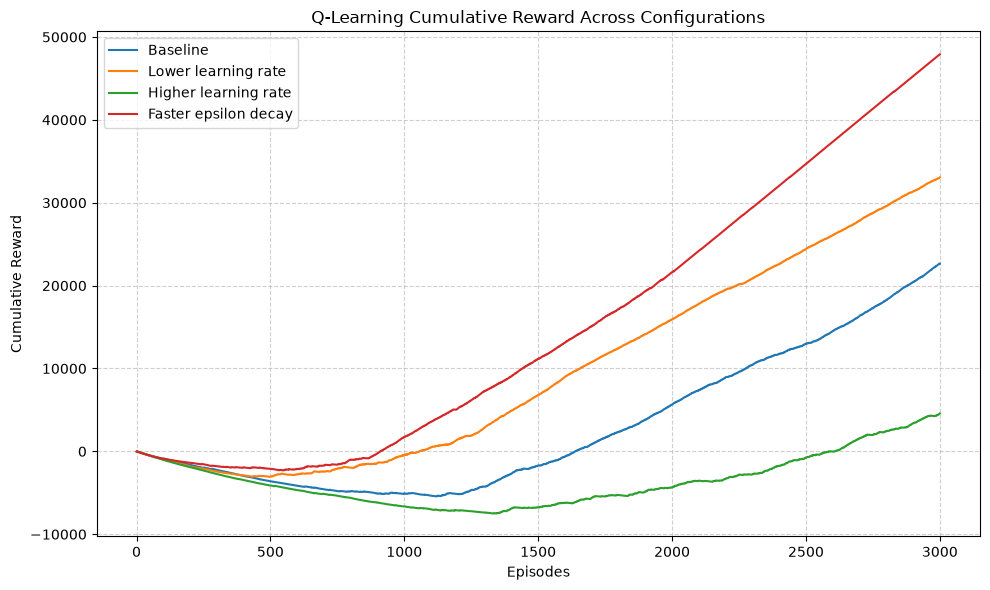

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Ensure matplotlib is set for notebook inline plotting
%matplotlib inline

plt.figure(figsize=(10, 6))

for exp in EXPERIMENTS_TO_RUN:
    name = exp["name"]
    label = exp["label"]
    monitor_path = RESULTS_DIRECTORY / f"{name}_monitor.csv"

    if not monitor_path.exists():
        continue

    print(f"\n{monitor_path.name}")
    # Read CSV skipping lines starting with #
    df = pd.read_csv(monitor_path, comment="#")
    print("Columns found:", list(df.columns))

    if df.empty or "r" not in df.columns:
        continue

    # 1. Calculate episode numbers (1, 2, 3, ...)
    df["episode"] = range(1, len(df) + 1)

    # 2. Calculate cumulative reward across episodes
    df["cumulative_reward"] = df["r"].cumsum()

    # 3. Plot Episode (X) vs Cumulative Reward (Y)
    plt.plot(df["episode"], df["cumulative_reward"], label=label)

plt.xlabel("Episodes")
plt.ylabel("Cumulative Reward")
plt.title("Q-Learning Cumulative Reward Across Configurations")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

save_figure("qlearning_training_learning_curves.png")

baseline_monitor.csv — columns: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']
  Plotted 3000 episodes (window=150).
low_alpha_monitor.csv — columns: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']
  Plotted 3000 episodes (window=150).
high_alpha_monitor.csv — columns: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']
  Plotted 3000 episodes (window=150).
fast_epsilon_decay_monitor.csv — columns: ['r', 'l', 't', 'reason', 'apples_collected', 'total_reward']
  Plotted 3000 episodes (window=150).


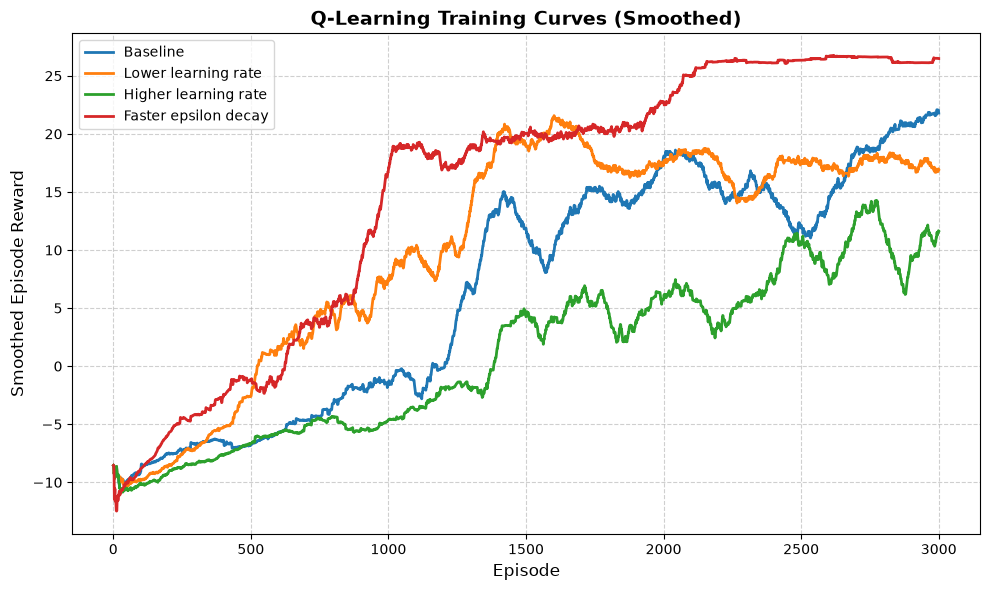

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

%matplotlib inline

plt.figure(figsize=(10, 6))
loaded_any = False

for exp in EXPERIMENTS_TO_RUN:
    name = exp["name"]
    label = exp["label"]
    monitor_path = RESULTS_DIRECTORY / f"{name}_monitor.csv"

    if not monitor_path.exists():
        print(f"Skipping (file not found): {monitor_path.name}")
        continue

    try:
        # Gym monitor CSVs have one comment line, then the real header row.
        # Skip lines starting with '#', then read normally.
        df = pd.read_csv(monitor_path, comment="#")
        print(f"{monitor_path.name} — columns: {list(df.columns)}")

        if df.empty or "r" not in df.columns:
            print(f"  Skipping: no 'r' column or empty.")
            continue

        df = df.reset_index(drop=True)
        df["episode"] = df.index + 1

        # Adaptive rolling window: ~5% of episodes, minimum 10
        window = max(10, len(df) // 20)
        df["smoothed_reward"] = df["r"].rolling(window, min_periods=1).mean()

        plt.plot(df["episode"], df["smoothed_reward"], label=label, linewidth=2)
        print(f"  Plotted {len(df)} episodes (window={window}).")
        loaded_any = True

    except Exception as e:
        print(f"  Error processing {monitor_path.name}: {e}")

if loaded_any:
    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("Smoothed Episode Reward", fontsize=12)
    plt.title(
        "Q-Learning Training Curves (Smoothed)",
        fontsize=14,
        fontweight="bold",
    )
    plt.legend(loc="upper left")
    plt.grid(True, linestyle="--", alpha=0.6)
    save_figure("qlearning_training_learning_curves.png")
else:
    print("No data plotted — check that training has completed and monitor CSVs exist.")


── Evaluating: Baseline ──────────────────────────────────────────
   Loading Q-table from: as4_qlearning_baseline.pkl
   States in Q-table : 811
   Total timesteps   : 1,048,335
   Final epsilon     : 0.2230
   Ep   1/50  reward= +34.17  steps=  96  apples=2  [success]
   Ep 2: flushed 11 stale reset steps
   Ep   2/50  reward= +25.06  steps=  19  apples=2  [success]
   Ep 3: flushed 11 stale reset steps
   Ep   3/50  reward=  -7.19  steps= 157  apples=1  [enemy]
   Ep   4/50  reward= +34.17  steps=  96  apples=2  [success]
   Ep 5: flushed 11 stale reset steps
   Ep   5/50  reward= +25.06  steps=  19  apples=2  [success]
   Ep 6: flushed 11 stale reset steps
   Ep   6/50  reward=  -7.19  steps= 157  apples=1  [enemy]
   Ep   7/50  reward= +34.17  steps=  96  apples=2  [success]
   Ep 8: flushed 11 stale reset steps
   Ep   8/50  reward= +25.06  steps=  19  apples=2  [success]
   Ep 9: flushed 11 stale reset steps
   Ep   9/50  reward=  -7.19  steps= 157  apples=1  [enemy]
   Ep  10/

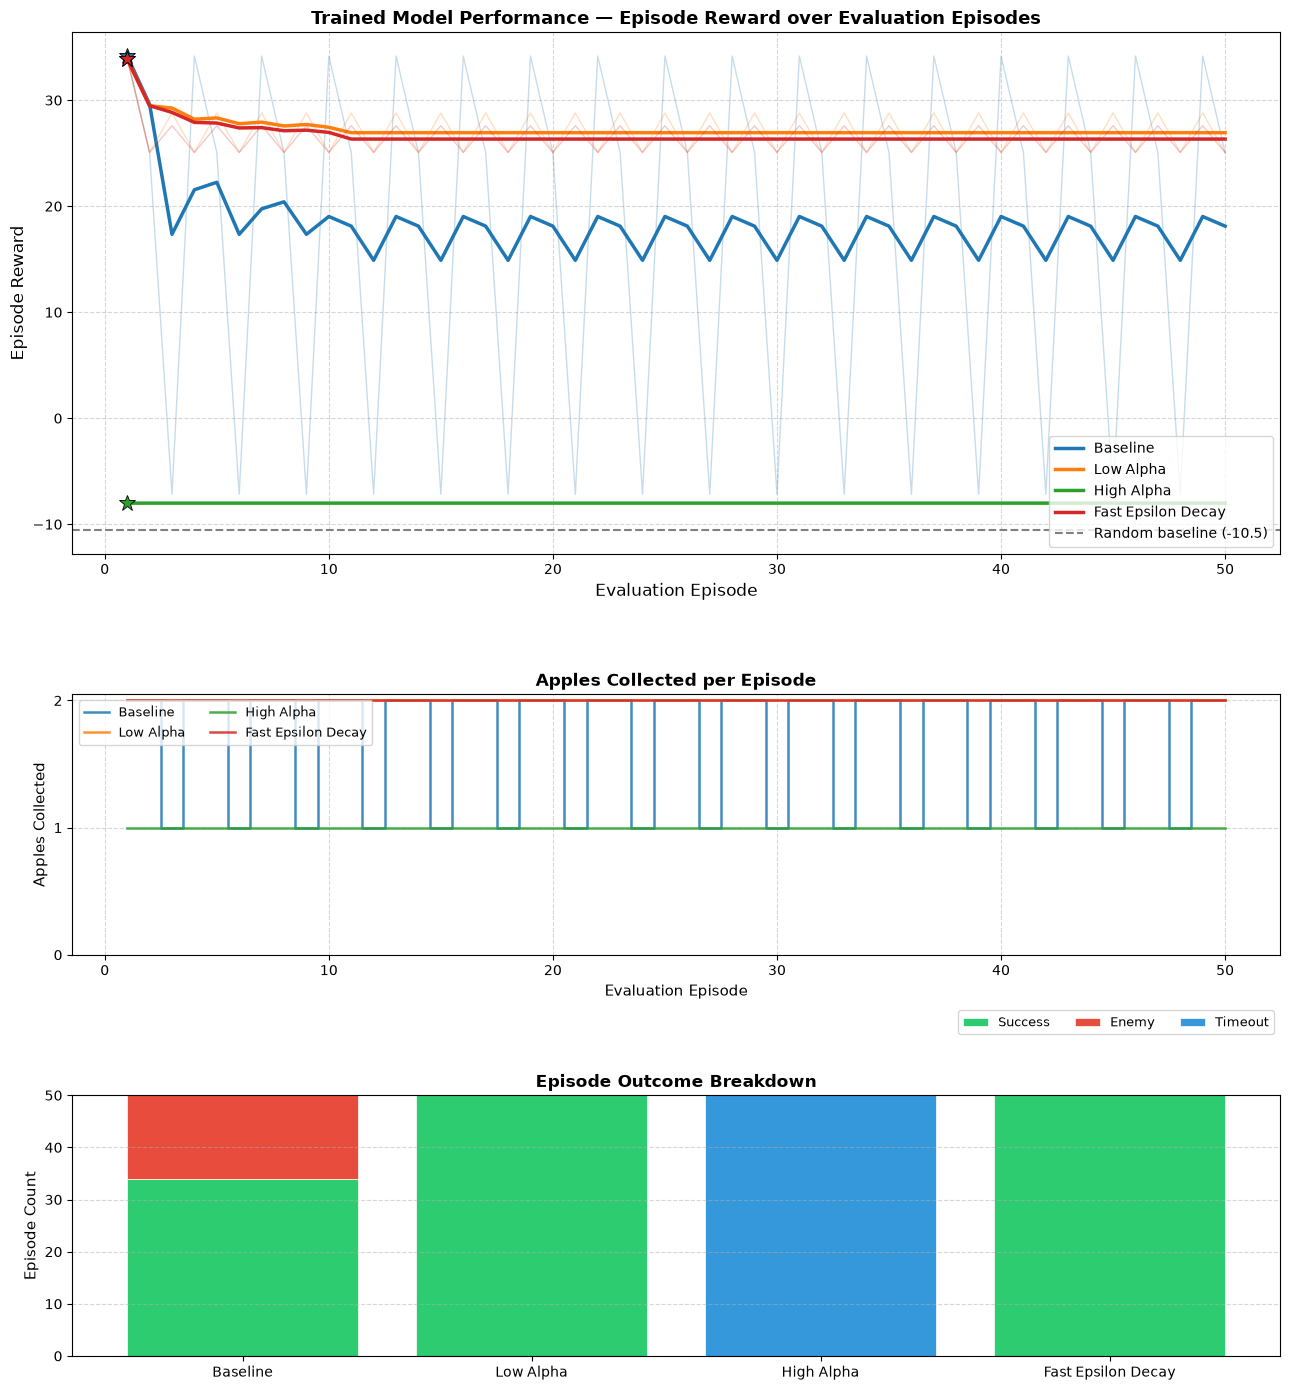


Figure saved to results/trained_model_evaluation.png


In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import time
from pathlib import Path

%matplotlib inline
HEADLESS = False

# ── 1. Configuration ─────────────────────────────────────────────────────────
EVAL_EPISODES      = 50
EVAL_PORT          = 8770
EVAL_DETERMINISTIC = True

EXPERIMENTS_TO_EVAL = [
    {"name": "baseline",           "label": "Baseline"},
    {"name": "low_alpha",          "label": "Low Alpha"},
    {"name": "high_alpha",         "label": "High Alpha"},
    {"name": "fast_epsilon_decay", "label": "Fast Epsilon Decay"},
]

# ── 2. Run each model sequentially ───────────────────────────────────────────
all_eval_results = {}
eval_summary     = []

for exp in EXPERIMENTS_TO_EVAL:
    name  = exp["name"]
    label = exp["label"]

    # Locate saved Q-table
    model_path = MODELS_DIRECTORY / f"as4_qlearning_{name}"
    if not model_path.exists():
        model_path = MODELS_DIRECTORY / f"as4_qlearning_{name}.pkl"
    if not model_path.exists():
        print(f"[MISSING] {model_path.name} — skipping {label}.")
        continue

    print(f"\n── Evaluating: {label} ──────────────────────────────────────────")
    print(f"   Loading Q-table from: {model_path.name}")

    try:
        agent = QLearningAgent.load(model_path)
        print(f"   States in Q-table : {len(agent.q_table):,}")
        print(f"   Total timesteps   : {agent.num_timesteps:,}")
        print(f"   Final epsilon     : {agent.epsilon_current:.4f}")
    except Exception as e:
        print(f"   [ERROR] Could not load agent: {e}")
        continue

    eval_env = AS4GodotEnv(headless=HEADLESS, port=EVAL_PORT)

    try:
        ep_rewards  = []
        ep_steps    = []
        ep_apples   = []
        ep_outcomes = []

        for ep in range(1, EVAL_EPISODES + 1):

            # ── Reset and flush stale state ───────────────────────────────
            observation, info = eval_env.reset(seed=SEED if ep == 1 else None)

            flush_attempts = 0
            while info.get("apples_collected", 0) > 0 or not info.get("is_on_floor", True):
                observation, _, _, _, info = eval_env.step(0)
                flush_attempts += 1
                if flush_attempts > 10:
                    break
            if flush_attempts > 0:
                print(f"   Ep {ep}: flushed {flush_attempts} stale reset steps")

            # ── Run episode ───────────────────────────────────────────────
            ep_reward  = 0.0
            ep_step    = 0
            terminated = False
            truncated  = False

            while not (terminated or truncated):
                action, _ = agent.predict(observation, deterministic=EVAL_DETERMINISTIC)
                observation, reward, terminated, truncated, info = eval_env.step(action)
                ep_reward += reward
                ep_step   += 1

            ep_rewards.append(ep_reward)
            ep_steps.append(ep_step)
            ep_apples.append(info.get("apples_collected", 0))
            ep_outcomes.append(info.get("reason", "unknown"))

            print(
                f"   Ep {ep:>3}/{EVAL_EPISODES}"
                f"  reward={ep_reward:+7.2f}"
                f"  steps={ep_step:>4}"
                f"  apples={info.get('apples_collected', 0)}"
                f"  [{info.get('reason','?')}]"
            )

    finally:
        eval_env.close()
        del agent

    # ── Store results ─────────────────────────────────────────────────────
    df = pd.DataFrame({
        "episode":          range(1, EVAL_EPISODES + 1),
        "reward":           ep_rewards,
        "steps":            ep_steps,
        "apples_collected": ep_apples,
        "outcome":          ep_outcomes,
    })
    df.to_csv(RESULTS_DIRECTORY / f"{name}_eval_results.csv", index=False)
    all_eval_results[name] = (label, df)

    completion_rate = sum(1 for o in ep_outcomes if o == "success") / EVAL_EPISODES
    eval_summary.append({
        "Configuration":   label,
        "Mean Reward":     round(float(np.mean(ep_rewards)), 2),
        "Reward Std":      round(float(np.std(ep_rewards)),  2),
        "Mean Steps":      round(float(np.mean(ep_steps)),   1),
        "Mean Apples":     round(float(np.mean(ep_apples)),  2),
        "Completion Rate": f"{completion_rate:.0%}",
    })

# ── 3. Summary Table ─────────────────────────────────────────────────────────
print("\n── Evaluation Summary ───────────────────────────────────────────────")
summary_df = pd.DataFrame(eval_summary)
summary_df.to_csv(RESULTS_DIRECTORY / "eval_summary.csv", index=False)
print(summary_df.to_string(index=False))

# ── 4. Plot ───────────────────────────────────────────────────────────────────
if not all_eval_results:
    print("No evaluation data to plot.")
else:
    palette = plt.cm.tab10.colors
    fig, axes = plt.subplots(
        3, 1,
        figsize=(13, 14),
        gridspec_kw={"height_ratios": [3, 1.5, 1.5]},
    )

    # ── 4a. Per-episode reward with smoothed trend ────────────────────────
    ax_main = axes[0]

    for idx, exp in enumerate(EXPERIMENTS_TO_EVAL):
        name = exp["name"]
        if name not in all_eval_results:
            continue
        label, df = all_eval_results[name]
        color = palette[idx % len(palette)]

        ax_main.plot(df["episode"], df["reward"],
                     color=color, alpha=0.25, linewidth=1)

        window   = max(3, EVAL_EPISODES // 5)
        smoothed = df["reward"].rolling(window, min_periods=1).mean()
        ax_main.plot(df["episode"], smoothed,
                     color=color, linewidth=2.5, label=label)

        best_ep  = int(df["reward"].idxmax()) + 1
        best_val = df["reward"].max()
        ax_main.plot(best_ep, best_val,
                     marker="*", markersize=12, color=color,
                     markeredgecolor="black", markeredgewidth=0.6, zorder=5)

    ax_main.axhline(
        y=random_summary["mean_reward"],
        color="gray", linestyle="--", linewidth=1.5,
        label=f"Random baseline ({random_summary['mean_reward']:.1f})",
    )
    ax_main.set_xlabel("Evaluation Episode", fontsize=12)
    ax_main.set_ylabel("Episode Reward", fontsize=12)
    ax_main.set_title(
        "Trained Model Performance — Episode Reward over Evaluation Episodes",
        fontsize=13, fontweight="bold",
    )
    ax_main.legend(loc="lower right", fontsize=10)
    ax_main.grid(True, linestyle="--", alpha=0.5)

    # ── 4b. Apples collected per episode ─────────────────────────────────
    ax_apple = axes[1]

    for idx, exp in enumerate(EXPERIMENTS_TO_EVAL):
        name = exp["name"]
        if name not in all_eval_results:
            continue
        label, df = all_eval_results[name]
        color = palette[idx % len(palette)]

        ax_apple.step(df["episode"], df["apples_collected"],
                      where="mid", color=color, linewidth=1.8,
                      alpha=0.85, label=label)

    ax_apple.set_yticks([0, 1, 2])
    ax_apple.set_ylabel("Apples Collected", fontsize=11)
    ax_apple.set_xlabel("Evaluation Episode", fontsize=11)
    ax_apple.set_title("Apples Collected per Episode", fontsize=12, fontweight="bold")
    ax_apple.legend(loc="upper left", fontsize=9, ncol=2)
    ax_apple.grid(True, linestyle="--", alpha=0.5)

    # ── 4c. Outcome breakdown stacked bar ────────────────────────────────
    ax_bar     = axes[2]
    outcomes   = ["success", "enemy", "fall", "timeout", "unknown"]
    bar_colors = {
        "success": "#2ecc71",
        "enemy":   "#e74c3c",
        "fall":    "#e67e22",
        "timeout": "#3498db",
        "unknown": "#95a1a5",
    }

    outcome_counts    = {o: [] for o in outcomes}
    bar_config_labels = []

    for exp in EXPERIMENTS_TO_EVAL:
        name = exp["name"]
        if name not in all_eval_results:
            continue
        label, df = all_eval_results[name]
        bar_config_labels.append(label)
        counts = df["outcome"].value_counts()
        for o in outcomes:
            outcome_counts[o].append(counts.get(o, 0))

    x_pos   = np.arange(len(bar_config_labels))
    bottoms = np.zeros(len(bar_config_labels))

    for o in outcomes:
        vals = np.array(outcome_counts[o])
        if vals.sum() == 0:
            continue
        ax_bar.bar(x_pos, vals, bottom=bottoms,
                   color=bar_colors[o], label=o.capitalize(),
                   edgecolor="white", linewidth=0.5)
        bottoms += vals

    ax_bar.set_xticks(x_pos)
    ax_bar.set_xticklabels(bar_config_labels, fontsize=10)
    ax_bar.set_ylabel("Episode Count", fontsize=11)
    ax_bar.set_title("Episode Outcome Breakdown", fontsize=12, fontweight="bold")
    ax_bar.legend(loc="upper right", fontsize=9, ncol=len(outcomes),
                  bbox_to_anchor=(1.0, 1.35))
    ax_bar.grid(True, axis="y", linestyle="--", alpha=0.5)

    plt.tight_layout(h_pad=3.0)
    save_figure("trained_model_evaluation.png")
    print("\nFigure saved to results/trained_model_evaluation.png")